# 04 — Adapter evaluation and error analysis

We evaluate the QLoRA adapter from notebook 03 on the same validation regions as the baseline. The comparison covers classification accuracy, oracle-type transcription, and transcription routed by predicted type.

The default run remains `multitask_smoke`, trained on 64 regions. Its results serve as an implementation check rather than evidence that full training improves recognition.

Prepared data, baseline results, and the checkpoint directory are reused from disk. Notebooks 01–03 do not need to run again. A completed matching adapter evaluation is also reused without loading Qwen or performing new inference.

In [ ]:
import csv
import json
import sys
from pathlib import Path

import torch
from IPython.display import display
from PIL import Image

# Locate the existing source directory without a machine-specific path.
CWD = Path.cwd().resolve()
CANDIDATES = [candidate for parent in (CWD, *CWD.parents) for candidate in (parent, parent / "src")]
PACKAGE = next(
    (
        candidate
        for candidate in CANDIDATES
        if (candidate / "rukopys" / "evaluate.py").is_file() and (candidate / "work").is_dir()
    ),
    None,
)

if PACKAGE is None:
    raise FileNotFoundError(
        "Open the notebook from the project directory or one of its subdirectories. "
        "Place the rukopys package inside the existing src directory, next to work."
    )

if str(PACKAGE) not in sys.path:
    sys.path.insert(0, str(PACKAGE))

from rukopys.config import CLASS_PROMPT, PROMPTS
from rukopys.evaluate import evaluate
from rukopys.metrics import edit_distance
from rukopys.models import load_qwen
from rukopys.utils import atomic_json, digest, file_digest, read_json

ROOT = (PACKAGE / "work").resolve()
RUN_NAME = "multitask_smoke"  # Use gold_multitask after full training.
REUSE_COMPLETED_RESULTS = True
BASELINE_PATH = ROOT / "outputs" / "baseline.json"
OUTPUT = ROOT / "outputs" / f"{RUN_NAME}_validation.json"
RUN_DIR = ROOT / "runs" / RUN_NAME

print("Python:", sys.version.split()[0])
print("Source directory:", PACKAGE.name)
print("Experiment directory:", ROOT.relative_to(PACKAGE))
print("Evaluation output:", OUTPUT.relative_to(PACKAGE))

Python: 3.12.5
Source directory: src
Experiment directory: work
Evaluation output: work\outputs\multitask_smoke_validation.json


## Check the checkpoint and evaluation protocol

We keep the existing environment without automatically reinstalling dependencies. Evaluation requires the prepared validation manifest, a completed baseline, and a fully written adapter checkpoint.

The baseline supplies the pixel and token budgets. Model revision, quantization, dtype, package versions, and prompts must match between the recorded baseline and adapter protocols; the adapter is the intended difference.

Existing adapter results are checked against the validation manifest, region order, evaluation settings, and current adapter fingerprint. A complete match skips model loading. An incomplete match resumes inference; a mismatch stops execution without replacing the saved evaluation.

In [ ]:
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

for path in (
    BASELINE_PATH,
    ROOT / "project.json",
    ROOT / "data" / "validation.json",
    RUN_DIR / "latest.json",
):
    if not path.is_file():
        raise FileNotFoundError(f"Missing required artifact: {path.relative_to(PACKAGE)}")

baseline = read_json(BASELINE_PATH)
validation = read_json(ROOT / "data" / "validation.json")
project = read_json(ROOT / "project.json")

if not validation:
    raise ValueError("The validation manifest is empty.")

if not baseline.get("complete") or "summary" not in baseline:
    raise ValueError("A completed baseline evaluation is required.")

if baseline["config"]["manifest"] != digest(validation):
    raise ValueError("The validation manifest differs from the baseline.")

if [row["id"] for row in baseline["results"]] != [row["id"] for row in validation]:
    raise ValueError("The baseline does not cover the same validation regions.")

if baseline["config"]["prompts"] != PROMPTS or baseline["config"]["class_prompt"] != CLASS_PROMPT:
    raise ValueError("Current prompts differ from the baseline.")

CHECKPOINT = Path(read_json(RUN_DIR / "latest.json")["checkpoint"]).resolve()

if CHECKPOINT.parent != RUN_DIR.resolve():
    raise ValueError("The checkpoint must belong to the selected run directory.")

for name in (
    "COMPLETE",
    "adapter_model.safetensors",
    "adapter_config.json",
    "run_config.json",
):
    if not (CHECKPOINT / name).is_file():
        raise FileNotFoundError(f"Incomplete checkpoint: missing {name}.")

baseline_protocol = baseline["config"]["protocol"]
training_config = read_json(CHECKPOINT / "run_config.json")
MAX_PIXELS = baseline_protocol["max_pixels"]
MAX_NEW_TOKENS = baseline["config"]["max_tokens"]
ADAPTER_SHA256 = file_digest(CHECKPOINT / "adapter_model.safetensors")
PROTOCOL_KEYS = (
    "model_id",
    "model_revision",
    "quantized",
    "dtype",
    "max_pixels",
    "packages",
)

if (
    baseline_protocol["model_id"] != project["model_id"]
    or baseline_protocol["model_revision"] != project.get("model_revision")
    or baseline_protocol["quantized"] is not True
    or baseline_protocol.get("adapter_sha256") is not None
):
    raise ValueError("The baseline does not match the project's base model.")

if (
    training_config["model_revision"] != project["model_revision"]
    or training_config["protocol"]["max_pixels"] != MAX_PIXELS
):
    raise ValueError("The checkpoint revision or pixel budget differs.")

saved = read_json(OUTPUT) if OUTPUT.is_file() else None
USE_SAVED_RESULTS = False

if saved is not None:
    expected_config = {
        "manifest": digest(validation),
        "protocol": saved["config"]["protocol"],
        "prompts": PROMPTS,
        "class_prompt": CLASS_PROMPT,
        "max_tokens": MAX_NEW_TOKENS,
    }

    if saved["config"] != expected_config:
        raise ValueError("The saved adapter evaluation uses different settings.")

    saved_protocol = saved["config"]["protocol"]

    if saved_protocol.get("adapter_sha256") != ADAPTER_SHA256:
        raise ValueError("The saved evaluation belongs to different adapter weights.")

    for key in PROTOCOL_KEYS:
        if saved_protocol[key] != baseline_protocol[key]:
            raise ValueError(f"Saved baseline/adapter protocol mismatch: {key}.")

    saved_results = saved.get("results", [])

    if [row["id"] for row in saved_results] != [
        row["id"] for row in validation[: len(saved_results)]
    ]:
        raise ValueError("The saved evaluation does not match the validation order.")

    USE_SAVED_RESULTS = (
        REUSE_COMPLETED_RESULTS
        and saved.get("complete", False)
        and len(saved_results) == len(validation)
        and "summary" in saved
    )

print("Checkpoint:", CHECKPOINT.relative_to(PACKAGE))
print("Validation regions:", len(validation))
print("Pixel budget:", MAX_PIXELS)
print("Generation token budget:", MAX_NEW_TOKENS)
print("Reusing completed evaluation:", USE_SAVED_RESULTS)

PyTorch: 2.7.1+cu126
CUDA available: True
Checkpoint: work\runs\multitask_smoke\checkpoint_000031
Validation regions: 5082
Pixel budget: 262144
Generation token budget: 512
Reusing completed evaluation: True


In [3]:
if USE_SAVED_RESULTS:
    protocol = saved["config"]["protocol"]
    print("Reusing the recorded evaluation protocol; model loading is skipped.")
else:
    if not torch.cuda.is_available():
        raise RuntimeError("Select a CUDA-enabled kernel to run or resume inference.")

    print("GPU:", torch.cuda.get_device_name(0))
    model, processor, protocol = load_qwen(
        ROOT,
        adapter=CHECKPOINT,
        quantized=True,
        max_pixels=MAX_PIXELS,
    )

for key in PROTOCOL_KEYS:
    if baseline_protocol[key] != protocol[key]:
        raise RuntimeError(
            f"Baseline protocol mismatch: {key}. "
            "Restore the baseline environment and settings before comparing."
        )

if protocol.get("adapter_sha256") != ADAPTER_SHA256:
    raise ValueError("The adapter fingerprint does not match the checkpoint.")

print(json.dumps(protocol, ensure_ascii=False, indent=2))
print("Baseline protocol checks passed.")

Reusing the recorded evaluation protocol; model loading is skipped.
{
  "model_id": "Qwen/Qwen3-VL-4B-Instruct",
  "model_revision": "ebb281ec70b05090aa6165b016eac8ec08e71b17",
  "quantized": true,
  "dtype": "torch.bfloat16",
  "max_pixels": 262144,
  "adapter_sha256": "565cc647b703b93c2e4257a0aa7b9a4d95a7326915e174873d5d045936228e06",
  "packages": {
    "torch": "2.7.1+cu126",
    "transformers": "4.57.6",
    "peft": "0.21.2",
    "bitsandbytes": "0.49.0",
    "pillow": "11.1.0"
  }
}
Baseline protocol checks passed.


## Evaluate the full validation dataset

We reuse a complete matching evaluation when `REUSE_COMPLETED_RESULTS = True`. This reads the saved predictions and summary without new inference or changes to the result file. The recorded runtime protocol is compared with the baseline; the current hardware and package versions are not revalidated for this read-only path.

If results are missing, evaluation creates them. If the matching output contains partial results, completed regions are skipped after loading the adapter. Starting or resuming inference requires the same runtime protocol as the baseline and saved evaluation.

New predictions are saved after each region. Keep the output file and checkpoint directory to preserve progress after an interruption.

Transcription uses reference bounding boxes. The raw CER metrics exclude official text normalization and detector errors, so they are not the complete Kaggle composite score.

In [4]:
if USE_SAVED_RESULTS:
    summary = saved["summary"]
    print("Reusing completed adapter evaluation; no new inference is needed.")
else:
    summary = evaluate(
        ROOT,
        model,
        processor,
        protocol,
        OUTPUT,
        max_tokens=MAX_NEW_TOKENS,
    )

print(json.dumps(summary, ensure_ascii=False, indent=2))
print("Evaluation results:", OUTPUT.relative_to(PACKAGE))

Reusing completed adapter evaluation; no new inference is needed.
{
  "oracle": {
    "n": 4955,
    "corpus_raw_cer": 0.8763900713864693,
    "mean_region_raw_cer": 1.2017441475896855
  },
  "routed": {
    "n": 4955,
    "corpus_raw_cer": 0.8683738293273954,
    "mean_region_raw_cer": 0.9054635239405988
  },
  "classification_accuracy": 0.9334907516725699,
  "invalid_labels": 0,
  "by_type": {
    "handwritten": {
      "n": 4277,
      "corpus_raw_cer": 0.8643858919593241,
      "mean_region_raw_cer": 0.9057360914269461
    },
    "printed": {
      "n": 88,
      "corpus_raw_cer": 2.8126168224299066,
      "mean_region_raw_cer": 9.37067429941073
    },
    "formula": {
      "n": 472,
      "corpus_raw_cer": 0.645095670968152,
      "mean_region_raw_cer": 0.5888477169505396
    },
    "table": {
      "n": 23,
      "corpus_raw_cer": 1.033255269320843,
      "mean_region_raw_cer": 0.700787760418944
    },
    "annotation": {
      "n": 95,
      "corpus_raw_cer": 2.6610978520286395

## Compare with the baseline

We compare the same regions, prompts, token budget, model revision, quantization, resolution, dtype, and recorded package versions. The adapter is the intended difference.

Lower CER and higher classification accuracy indicate better performance. CER values above 100% are retained rather than clipped.

A matching comparison file is reused. If it is absent, this cell creates it from the evaluation results. An existing comparison with different contents is preserved and raises a configuration error.

In [ ]:
tuned = read_json(OUTPUT)

if not baseline.get("complete") or not tuned.get("complete"):
    raise ValueError("Both evaluations must be complete.")

for key in ("manifest", "prompts", "class_prompt", "max_tokens"):
    if baseline["config"][key] != tuned["config"][key]:
        raise ValueError(f"Evaluation mismatch: {key}.")

for key in PROTOCOL_KEYS:
    if baseline_protocol[key] != tuned["config"]["protocol"][key]:
        raise ValueError(f"Comparison protocol mismatch: {key}.")

if tuned["config"]["protocol"]["adapter_sha256"] != ADAPTER_SHA256:
    raise ValueError("Comparison adapter fingerprint mismatch.")

if [row["id"] for row in baseline["results"]] != [row["id"] for row in tuned["results"]]:
    raise ValueError("Evaluated regions differ.")

comparison = {
    "run_name": RUN_NAME,
    "checkpoint": str(CHECKPOINT),
    "baseline": baseline["summary"],
    "tuned": tuned["summary"],
    "scope": (
        "Reference bounding boxes; raw CER without official normalization; "
        "validation used for model selection"
    ),
}
comparison_path = ROOT / "outputs" / f"{RUN_NAME}_comparison.json"

if comparison_path.is_file():
    if read_json(comparison_path) != comparison:
        raise ValueError(
            "The existing comparison differs from the current results. "
            "Keep it and choose a separate comparison filename for a new report."
        )

    print("Existing comparison retained:", comparison_path.relative_to(PACKAGE))
else:
    atomic_json(comparison_path, comparison)
    print("Comparison saved:", comparison_path.relative_to(PACKAGE))

print(json.dumps(baseline["summary"], ensure_ascii=False, indent=2))
print(json.dumps(tuned["summary"], ensure_ascii=False, indent=2))

for branch in ("oracle", "routed"):
    for metric in ("corpus_raw_cer", "mean_region_raw_cer"):
        before = baseline["summary"][branch].get(metric)
        after = tuned["summary"][branch].get(metric)

        if before is not None and after is not None:
            print(
                f"{branch} / {metric}: {before:.2%} -> {after:.2%}; "
                f"change {(after - before) * 100:+.2f} percentage points"
            )

Existing comparison retained: work\outputs\multitask_smoke_comparison.json
{
  "oracle": {
    "n": 4955,
    "corpus_raw_cer": 0.7770187962538476,
    "mean_region_raw_cer": 0.9334420837426898
  },
  "routed": {
    "n": 4955,
    "corpus_raw_cer": 0.7455432575807192,
    "mean_region_raw_cer": 0.6750975904381371
  },
  "classification_accuracy": 0.9191263282172373,
  "invalid_labels": 0,
  "by_type": {
    "handwritten": {
      "n": 4277,
      "corpus_raw_cer": 0.707224133368616,
      "mean_region_raw_cer": 0.6333557085961372
    },
    "printed": {
      "n": 88,
      "corpus_raw_cer": 2.183644859813084,
      "mean_region_raw_cer": 7.041325857858004
    },
    "formula": {
      "n": 472,
      "corpus_raw_cer": 1.1546627677833576,
      "mean_region_raw_cer": 1.0561353584200837
    },
    "table": {
      "n": 23,
      "corpus_raw_cer": 0.6163934426229508,
      "mean_region_raw_cer": 0.5650560640982617
    },
    "annotation": {
      "n": 95,
      "corpus_raw_cer": 2.26491

## Review qualitative errors

We rank scorable regions by character edit count and export them for manual review. The CSV includes both oracle-type and routed predictions.

An existing review file is kept unchanged to preserve manual observations. This does not verify that the CSV matches a newly selected evaluation; use a separate review filename when intentionally reviewing different results.

The first eight examples are displayed when their crop files are available. Missing preview images do not prevent inspection of the saved text predictions.

Existing error review retained: work\outputs\multitask_smoke_error_review.csv


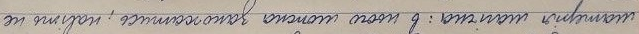

Region: 4fdefb87a09d9fd950c191bc
Type: handwritten -> handwritten
Reference: 'матерія магічна : в нього можна закохатись , навіть не'
Oracle-type prediction: 'відповідно до чинного законодавства. Відповідно до чинного законодавства. Відповідно до чинного законодавства. Відповідно до чинного законодавства. Відповідно до чинного законодавства. Відповідно до чинного законодавства. Відповідно до чинного законодавства. Відповідно до чинного законодавства. Відповідно до чинного законодавства. Відповідно до чинного законодавства. Відповідно до чинного законодавства. Відповідно до чинного законодавства. Відповідно до чинного законодавства. Відповідно до чинного законодавства. Відповідно до чинного законодавства. Відповідно до чинного законодавства. Відповідно до чинного законодавства. Відповідно до чинного законодавства. Відповідно до чинного законодавства. Відповідно до чинного законодавства. Відповідно до чинного законодавства. Відповідно до чинного законодавства. Відповідно до чинного закон

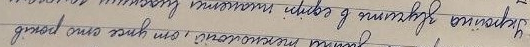

Region: 5a18fed3a76a629b551e65e3
Type: handwritten -> handwritten
Reference: 'Україна звучить в ефірі планети власними голосом.'
Oracle-type prediction: 'відповідно до чинного законодавства, яке встановлює порядок виборів, вибори відбуваються відповідно до чинного законодавства, яке встановлює порядок виборів, вибори відбуваються відповідно до чинного законодавства, яке встановлює порядок виборів, вибори відбуваються відповідно до чинного законодавства, яке встановлює порядок виборів, вибори відбуваються відповідно до чинного законодавства, яке встановлює порядок виборів, вибори відбуваються відповідно до чинного законодавства, яке встановлює порядок виборів, вибори відбуваються відповідно до чинного законодавства, яке встановлює порядок виборів, вибори відбуваються відповідно до чинного законодавства, яке встановлює порядок виборів, вибори відбуваються відповідно до чинного законодавства, яке встановлює порядок виборів, вибори відбуваються відповідно до чинного законодавства, яке вста

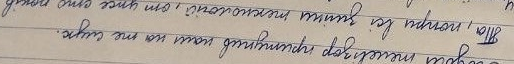

Region: 91143b59061880185b9b1219
Type: handwritten -> handwritten
Reference: 'Та , попри всі зміни технологій , от уже сто років'
Oracle-type prediction: 'відповідно до чинного законодавства, яке відповідає вимогам законодавства, яке відповідає вимогам законодавства, яке відповідає вимогам законодавства, яке відповідає вимогам законодавства, яке відповідає вимогам законодавства, яке відповідає вимогам законодавства, яке відповідає вимогам законодавства, яке відповідає вимогам законодавства, яке відповідає вимогам законодавства, яке відповідає вимогам законодавства, яке відповідає вимогам законодавства, яке відповідає вимогам законодавства, яке відповідає вимогам законодавства, яке відповідає вимогам законодавства, яке відповідає вимогам законодавства, яке відповідає вимогам законодавства, яке відповідає вимогам законодавства, яке відповідає вимогам законодавства, яке відповідає вимогам законодавства, яке відповідає вимогам законодавства, яке відповідає вимогам законодавства, яке відпов

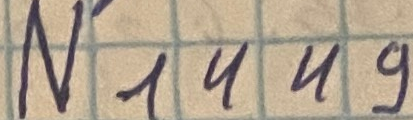

Region: 4910312d45b6b7e0e4346aa9
Type: handwritten -> handwritten
Reference: 'N 1449'
Oracle-type prediction: 'N ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч ч

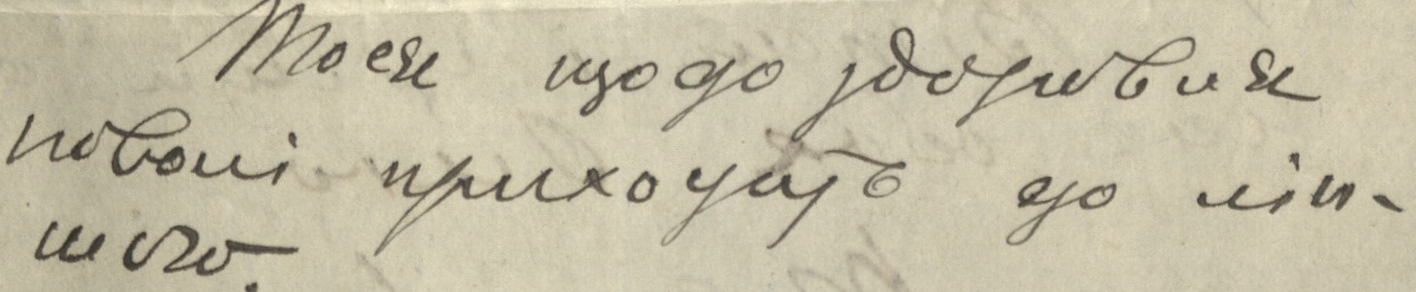

Region: 7ece3d06efe3e5d875e94d0a
Type: handwritten -> handwritten
Reference: 'поволі приходить до ліп-'
Oracle-type prediction: 'Може щодо розриву відносин з чиновником чи з чиновником чи з чиновником чи з чиновником чи з чиновником чи з чиновником чи з чиновником чи з чиновником чи з чиновником чи з чиновником чи з чиновником чи з чиновником чи з чиновником чи з чиновником чи з чиновником чи з чиновником чи з чиновником чи з чиновником чи з чиновником чи з чиновником чи з чиновником чи з чиновником чи з чиновником чи з чиновником чи з чиновником чи з чиновником чи з чиновником чи з чиновником чи з чиновником чи з чиновником чи з чиновником чи з чиновником чи з чиновником чи з чиновником чи з чиновником чи з чиновником чи з чиновником чи з чиновником чи з чиновником чи з чиновником чи з чиновником чи з чиновником чи з чиновником чи з чиновником чи з чиновником чи з чиновником чи з чиновником чи з чиновником чи з чиновником чи з чиновником чи з чиновником чи з чиновником чи з чиновником

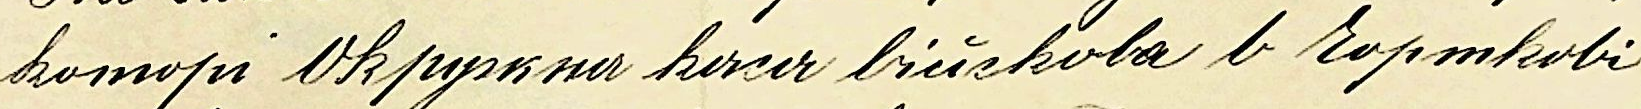

Region: 37ae531a853c1dbcc0028426
Type: handwritten -> handwritten
Reference: 'которі Окружна каса військова в Чорткові'
Oracle-type prediction: 'відповідно до відповідних норм відповідно до відповідних норм відповідно до відповідних норм відповідно до відповідних норм відповідно до відповідних норм відповідно до відповідних норм відповідно до відповідних норм відповідно до відповідних норм відповідно до відповідних норм відповідно до відповідних норм відповідно до відповідних норм відповідно до відповідних норм відповідно до відповідних норм відповідно до відповідних норм відповідно до відповідних норм відповідно до відповідних норм відповідно до відповідних норм відповідно до відповідних норм відповідно до відповідних норм відповідно до відповідних норм відповідно до відповідних норм відповідно до відповідних норм відповідно до відповідних норм відповідно до відповідних норм відповідно до відповідних норм відповідно до відповідних норм відповідно до відповідних норм відповідно до відп

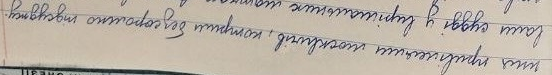

Region: 0512381a2ab57f820579de93
Type: handwritten -> handwritten
Reference: 'вали судді у вирішальних матчах. Аж дивно , яке багат-'
Oracle-type prediction: 'відповідно до чинного законодавства, яке встановлює відповідність між засобами відновлення та засобами відновлення, що відповідають цим засобам, відповідно до чинного законодавства, яке встановлює відповідність між засобами відновлення та засобами відновлення, що відповідають цим засобам, відповідно до чинного законодавства, яке встановлює відповідність між засобами відновлення та засобами відновлення, що відповідають цим засобам, відповідно до чинного законодавства, яке встановлює відповідність між засобами відновлення та засобами відновлення, що відповідають цим засобам, відповідно до чинного законодавства, яке встановлює відповідність між засобами відновлення та засобами відновлення, що відповідають цим засобам, відповідно до чинного законодавства, яке встановлює відповідність між засобами відновлення та засобами відновлення, 

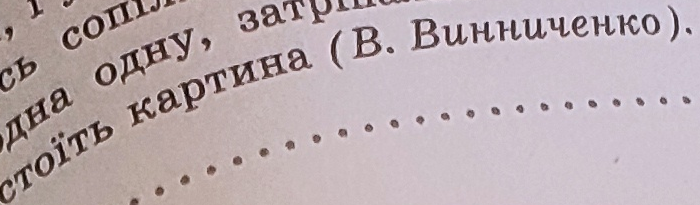

Region: 106e626a197358666f877e75
Type: printed -> printed
Reference: 'стоїть картина (В. Винниченко).'
Oracle-type prediction: 'дна одну, затримаються, відкриваються, відкриваються, відкриваються, відкриваються, відкриваються, відкриваються, відкриваються, відкриваються, відкриваються, відкриваються, відкриваються, відкриваються, відкриваються, відкриваються, відкриваються, відкриваються, відкриваються, відкриваються, відкриваються, відкриваються, відкриваються, відкриваються, відкриваються, відкриваються, відкриваються, відкриваються, відкриваються, відкриваються, відкриваються, відкриваються, відкриваються, відкриваються, відкриваються, відкриваються, відкриваються, відкриваються, відкриваються, відкриваються, відкриваються, відкриваються, відкриваються, відкриваються, відкриваються, відкриваються, відкриваються, відкриваються, відкриваються, відкриваються, відкриваються, відкриваються, відкриваються, відкриваються, відкриваються, відкриваються, відкриваються, відкриваються, відкрива

In [6]:
rows = [row for row in tuned["results"] if row["scorable"]]
rows.sort(
    key=lambda row: edit_distance(row["reference"], row["prediction"]),
    reverse=True,
)

review = ROOT / "outputs" / f"{RUN_NAME}_error_review.csv"
fields = [
    "id",
    "page_id",
    "source",
    "type",
    "predicted_type",
    "reference",
    "prediction",
    "routed_prediction",
    "edits",
    "manual_observation",
]

if not review.exists():
    with review.open("w", encoding="utf-8-sig", newline="") as file:
        writer = csv.DictWriter(file, fieldnames=fields)
        writer.writeheader()

        for row in rows:
            writer.writerow(
                {
                    **{key: row[key] for key in fields if key in row},
                    "routed_prediction": row["routed"]["prediction"],
                    "edits": edit_distance(row["reference"], row["prediction"]),
                    "manual_observation": "",
                }
            )

    print("Error review saved:", review.relative_to(PACKAGE))
else:
    print("Existing error review retained:", review.relative_to(PACKAGE))

for row in rows[:8]:
    if Path(row["crop_path"]).is_file():
        with Image.open(row["crop_path"]) as image:
            display(image.convert("RGB"))
    else:
        print("Crop preview is unavailable.")

    print("Region:", row["id"])
    print("Type:", row["type"], "->", row["predicted_type"])
    print("Reference:", repr(row["reference"]))
    print("Oracle-type prediction:", repr(row["prediction"]))
    print("Routed prediction:", repr(row["routed"]["prediction"]))

## Interpret the results

We record whether classification and transcription improved, which sources and region types remain difficult, and which patterns appear in the reviewed examples. Conclusions should follow the measured results rather than assume that training helped.

- Classification: [to be completed after review]
- Oracle-type transcription: [to be completed after review]
- Routed transcription: [to be completed after review]
- Recurring error patterns: [to be completed after review]

After evaluating the smoke adapter, we return to notebook 03 for a new full gold run. Once full training is complete, this notebook uses `RUN_NAME = "gold_multitask"`. Detector integration and test submission generation remain separate steps in notebook 06.